# Heart Disease Risk Prediction from Clinical Measurements
## Term Project — Part 2: Model Training, Tuning, Evaluation and the Final ML Pipeline

**Course:** DS5002 Data Science Tools and Techniques (Fall 2026) · **Instructor:** Dr. Asma Ahmad · **TA:** Burhan Hadi Butt
**Group 15:** Raza Ul Mustafa (26L-8030) · Ahmad Ali (26L-8015) · Gohar Maqsood (26L-8033)
**Part 2 prepared by:** Gohar Maqsood (26L-8033)

Part 1 (`01_data_cleaning_eda.ipynb`) cleaned the data, made the features and saved a fixed 80/20 train/test split. This notebook starts from those saved files.

**Research questions**

| | Question | Where |
|---|---|---|
| RQ1 | Can a tuned classifier reach **recall ≥ 0.90** for the disease class, with precision ≥ 0.80, on unseen patients? | Section 5 |
| RQ2 | How much does performance drop at a **hospital the model has not seen** (leave-one-hospital-out)? | Section 6.1 |
| RQ3 | Is "Cholesterol = 0" (missing cholesterol) a **shortcut** for the Swiss hospital rather than a medical signal? | Section 6.2 |
| RQ4 | Which features drive the predictions, and are they the same in every hospital? | Section 7 |

**Contents**

| Section | Content |
|---|---|
| 1 | Setup, data loading and the train / validation / test design |
| 2 | Features and the leakage-free preprocessing pipeline |
| 3 | Baselines and comparison of 8 models with 5-fold cross-validation |
| 4 | Hyperparameter tuning and model optimization |
| 5 | Decision threshold and the final test-set evaluation |
| 6 | Robustness: unseen hospitals (RQ2) and the cholesterol shortcut (RQ3) |
| 7 | Explaining the model: coefficients and SHAP (RQ4) |
| 8 | Final model selection and the saved ML pipeline |
| 9 | Summary, answers to the research questions and limitations |

---
# 1. Setup, Data Loading and the Train / Validation / Test Design

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import sklearn
import xgboost
import shap

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer, KNNImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder
from sklearn.feature_selection import SelectKBest, mutual_info_classif
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import (recall_score, precision_score, f1_score, accuracy_score, roc_auc_score,
                             confusion_matrix, roc_curve, precision_recall_curve)
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)   # library notices about future versions only

RANDOM_STATE = 42
DATA = Path("../data/processed")      # outputs of Part 1
FIG = Path("../reports/figures")       # figures of this notebook (prefix p2_)
MODELS = Path("../models")             # saved final pipeline
FIG.mkdir(parents=True, exist_ok=True)
MODELS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
pd.set_option("display.precision", 3)
print("scikit-learn", sklearn.__version__, "| xgboost", xgboost.__version__, "| shap", shap.__version__)

scikit-learn 1.9.1 | xgboost 3.4.1 | shap 0.54.1


### 1.1 Load the cleaned data and the saved split

`heart_clean.csv` still contains missing values on purpose. Filling them (imputation) is part of the model pipeline below, so it is learned **only from training data** in every step.

In [2]:
df = pd.read_csv(DATA / "heart_clean.csv")
TARGET = "HeartDisease"
CAT_COLS = ["Sex", "ExerciseAngina", "ChestPainType", "RestingECG", "ST_Slope"]
df[CAT_COLS] = df[CAT_COLS].astype(object)        # plain text columns; missing values stay NaN

train = df[df["split"] == "train"].copy()
test = df[df["split"] == "test"].copy()
print("All patients:", df.shape[0], "| train:", train.shape[0], "| test:", test.shape[0])

summary = (df.groupby(["split", "hospital"])[TARGET]
             .agg(patients="size", disease_rate="mean")
             .unstack("split"))
summary

All patients: 918 | train: 734 | test: 184


patients       disease_rate       
split             test train         test  train
hospital                                        
Cleveland           61   242        0.459  0.459
Hungary             58   235        0.362  0.362
Switzerland         25    98        0.920  0.939
VA Long Beach       40   159        0.750  0.742

### 1.2 How the data is used: train, validation and test

| Set | Patients | Used for |
|---|---|---|
| **Training** (inside cross-validation) | 4/5 of 734 in each fold | fitting the models |
| **Validation** (inside cross-validation) | 1/5 of 734 in each fold | comparing models, tuning, choosing the threshold |
| **Test** | 184 | **only once**, at the end, for the final model |

- With only 918 patients, one fixed validation set would be small and its result would depend on luck. So we use **stratified 5-fold cross-validation** on the training set: each patient is in the validation part exactly once, and we report the **mean ± standard deviation** of the 5 folds.
- The folds are stratified by **hospital and diagnosis together**, so every fold has the same mix of hospitals and disease rates.
- The 184 test patients are not touched until Section 5.2.

---
# 2. Features and the Leakage-Free Preprocessing Pipeline

**Features used** (11 clinical measurements + 2 missing-value flags from Part 1):

| Group | Columns | Preprocessing |
|---|---|---|
| Numeric | Age, RestingBP, Cholesterol, MaxHR, Oldpeak | median imputation → standard scaling |
| Binary | Sex, ExerciseAngina, FastingBS | most-frequent imputation → one 0/1 column |
| Nominal | ChestPainType, RestingECG | most-frequent imputation → one-hot encoding |
| Ordinal | ST_Slope (Up < Flat < Down) | most-frequent imputation → 0, 1, 2 |
| Flags | Cholesterol_missing, ST_Slope_missing | used as they are (0/1) |

**Not used as features:**
- `hospital`: it is used only to stratify the folds and for the unseen-hospital test (Section 6). Using it as a feature would let the model learn "which hospital" instead of "which patient".
- `MaxHR_pct`: Part 1 found r = 0.95 with MaxHR, so it repeats the same information. Section 4.3 checks that adding it back does not help.

**Why a Pipeline?** All preprocessing steps and the model are joined into **one object**. In cross-validation, the pipeline is fitted again inside every fold, so the medians, modes, means and standard deviations come only from that fold's training part. Nothing from the validation or test patients leaks into training.

In [3]:
NUM_FEATS = ["Age", "RestingBP", "Cholesterol", "MaxHR", "Oldpeak"]
BIN_FEATS = ["Sex", "ExerciseAngina", "FastingBS"]
NOM_FEATS = ["ChestPainType", "RestingECG"]
ORD_FEATS = ["ST_Slope"]
FLAG_FEATS = ["Cholesterol_missing", "ST_Slope_missing"]
FEATURES = NUM_FEATS + BIN_FEATS + NOM_FEATS + ORD_FEATS + FLAG_FEATS


def make_preprocess(num_feats=NUM_FEATS, flag_feats=FLAG_FEATS, imputer="median"):
    # median imputation then scaling; KNN imputation needs scaled values first
    if imputer == "median":
        num_steps = [("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]
    else:
        num_steps = [("scale", StandardScaler()), ("impute", KNNImputer(n_neighbors=5))]
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_feats),
        ("bin", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(drop="if_binary", sparse_output=False))]), BIN_FEATS),
        ("nom", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), NOM_FEATS),
        ("ord", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("encode", OrdinalEncoder(categories=[["Up", "Flat", "Down"]]))]), ORD_FEATS),
        ("flag", "passthrough", flag_feats),
    ])


def make_pipeline(model, **prep_args):
    # preprocessing + model in one object, so every fit happens on training data only
    return Pipeline([("prep", make_preprocess(**prep_args)), ("model", model)])


X_train, y_train = train[FEATURES], train[TARGET]
X_test, y_test = test[FEATURES], test[TARGET]

# 5 folds, stratified by hospital AND diagnosis
strata = train["hospital"] + " | " + train[TARGET].astype(str)
CV = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE).split(X_train, strata))

fold_info = pd.DataFrame([{"fold": i + 1, "train size": len(tr), "validation size": len(va),
                           "validation disease rate": y_train.iloc[va].mean()}
                          for i, (tr, va) in enumerate(CV)])
n_cols = make_preprocess().fit(X_train).get_feature_names_out().size
print("Columns after preprocessing:", n_cols)
fold_info

Columns after preprocessing: 18


,fold,train size,validation size,validation disease rate
0,1,587,147,0.551
1,2,587,147,0.558
2,3,587,147,0.558
3,4,587,147,0.551
4,5,588,146,0.548


---
# 3. Baselines and Comparison of 8 Models (5-fold Cross-Validation)

**Models and why we try them**

| Model | Type | Why |
|---|---|---|
| Majority class | baseline | Always predicts "disease" (the bigger class). Any useful model must beat it. |
| Logistic Regression | linear | Simple, fast, gives probabilities and readable coefficients. Strong baseline for small tabular data. |
| k-Nearest Neighbours | distance-based | Predicts from similar patients (Lecture 8). Needs scaled features. |
| Support Vector Machine (RBF) | kernel | Can draw curved boundaries between the classes. |
| Gaussian Naive Bayes | probabilistic | Very simple; assumes features are independent. |
| Decision Tree | tree | Easy to read, but one tree often overfits. |
| Random Forest | tree ensemble | Many trees on random parts of the data; less overfitting. |
| XGBoost | boosted trees | Strong on tabular data; adds trees one by one to fix earlier errors. |

**Metrics.** The disease class is the **positive** class. **Recall** (share of sick patients we catch) is the main metric, because a missed patient (false negative) is the costly error in screening. We also report precision, F1, ROC-AUC (ranking quality, independent of the threshold) and accuracy. All models use default settings here; tuning is in Section 4.

In [4]:
BASE_MODELS = {
    "Majority (baseline)": DummyClassifier(strategy="most_frequent"),
    "Logistic Regression": LogisticRegression(max_iter=5000),
    "kNN": KNeighborsClassifier(),
    "SVM (RBF)": SVC(probability=True, random_state=RANDOM_STATE),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "XGBoost": XGBClassifier(eval_metric="logloss", random_state=RANDOM_STATE, n_jobs=4),
}
SCORING = ["recall", "precision", "f1", "roc_auc", "accuracy"]


def cv_scores(pipe, X=X_train, y=y_train):
    res = cross_validate(pipe, X, y, cv=CV, scoring=SCORING)
    return {m: res[f"test_{m}"] for m in SCORING}


start = time.time()
base_scores = {name: cv_scores(make_pipeline(model)) for name, model in BASE_MODELS.items()}
print(f"8 models x 5 folds in {time.time() - start:.1f} s")


def mean_sd_table(scores):
    rows = {name: {m: f"{s[m].mean():.3f} ± {s[m].std():.3f}" for m in SCORING} for name, s in scores.items()}
    table = pd.DataFrame(rows).T
    order = sorted(scores, key=lambda n: scores[n]["roc_auc"].mean(), reverse=True)
    return table.loc[order]


base_table = mean_sd_table(base_scores)
base_table

8 models x 5 folds in 4.4 s


,recall,precision,f1,roc_auc,accuracy
Logistic Regression,0.832 ± 0.019,0.815 ± 0.012,0.823 ± 0.012,0.886 ± 0.005,0.802 ± 0.013
Naive Bayes,0.805 ± 0.042,0.824 ± 0.016,0.814 ± 0.024,0.877 ± 0.023,0.797 ± 0.023
Random Forest,0.823 ± 0.044,0.796 ± 0.035,0.808 ± 0.024,0.873 ± 0.019,0.783 ± 0.029
SVM (RBF),0.830 ± 0.023,0.796 ± 0.026,0.812 ± 0.018,0.871 ± 0.018,0.787 ± 0.022
XGBoost,0.815 ± 0.037,0.802 ± 0.025,0.808 ± 0.022,0.854 ± 0.014,0.786 ± 0.023
kNN,0.847 ± 0.033,0.773 ± 0.017,0.808 ± 0.021,0.839 ± 0.008,0.778 ± 0.024
Decision Tree,0.754 ± 0.028,0.742 ± 0.017,0.747 ± 0.011,0.714 ± 0.012,0.718 ± 0.011
Majority (baseline),1.000 ± 0.000,0.553 ± 0.004,0.712 ± 0.003,0.500 ± 0.000,0.553 ± 0.004


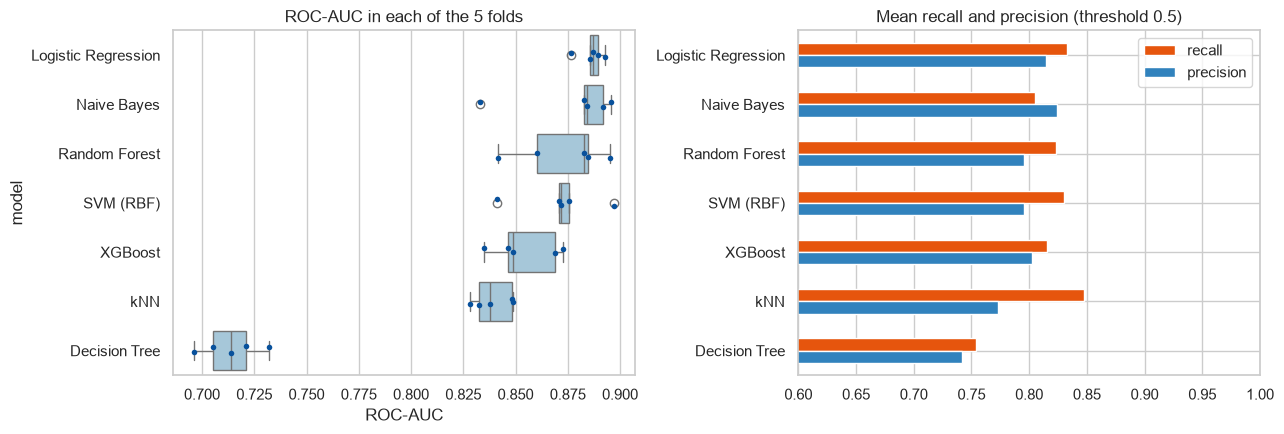

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
order = [n for n in base_table.index if n != "Majority (baseline)"]
auc_long = pd.DataFrame({n: base_scores[n]["roc_auc"] for n in order}).melt(var_name="model", value_name="ROC-AUC")
sns.boxplot(data=auc_long, y="model", x="ROC-AUC", order=order, color="#9ecae1", ax=axes[0])
sns.stripplot(data=auc_long, y="model", x="ROC-AUC", order=order, color="#08519c", size=4, ax=axes[0])
axes[0].set_title("ROC-AUC in each of the 5 folds")
means = pd.DataFrame({n: {"recall": base_scores[n]["recall"].mean(), "precision": base_scores[n]["precision"].mean()}
                      for n in order}).T
means.plot.barh(ax=axes[1], color=["#e6550d", "#3182bd"])
axes[1].invert_yaxis(); axes[1].set_xlim(0.6, 1.0); axes[1].set_title("Mean recall and precision (threshold 0.5)")
plt.tight_layout(); plt.savefig(FIG / "p2_cv_model_comparison.png", dpi=150); plt.show()

**What the comparison shows (5-fold CV, default settings, threshold 0.5):**
- **Every real model beats the baseline clearly.** The majority-class baseline has recall 1.000 (it calls everyone sick), but its ROC-AUC is 0.500 and accuracy only 0.553. This is why recall or accuracy alone can be misleading.
- **Logistic Regression is the best and the most stable:** ROC-AUC **0.886 ± 0.005**, recall 0.832, precision 0.815. Its fold-to-fold spread is the smallest of all models.
- Naive Bayes (0.877), Random Forest (0.873) and SVM (0.871) are close behind. XGBoost with default settings is lower (0.854).
- **kNN** has the highest recall at 0.5 (0.847) but the lowest precision of the real models (0.773).
- **A single Decision Tree is the weakest** (AUC 0.714): one deep tree memorizes the training folds (overfitting). Random Forest fixes this by averaging 300 trees.
- At the default threshold 0.5, **no model reaches recall 0.90** (best about 0.85). So Section 5 lowers the threshold to meet the recall target.

**Why does a simple linear model win?** The data is small (734 training patients) and the strongest signals (chest pain type, exercise angina, Oldpeak, sex) push the risk in one direction each, so a straight-line boundary is already a good fit. Complex models need more data to gain from their flexibility.